# CNN study: comparisons and error analysis

Load a completed study without retraining. Inspect preprocessing, capacity,
document length, false alarms, and missed attacks. Validation-selected thresholds
are development results. The test set has already been inspected in earlier work;
an untouched independent holdout is needed for stronger generalization claims.

## 1. Imports

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "cnn" / "cnn_study.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from cnn import cnn_study as study
from cnn import cnn_experiments as exp

torch.set_num_threads(4)
pd.set_option("display.max_columns", 16)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

## 2. Select the same completed run

Match the tuning notebook's smoke mode and run name. Test scoring defaults to disabled and rejects smoke studies.

In [2]:
SMOKE_MODE = False
RUN_NAME = "cnn_study_v2_full_01"
DEVICE_REQUEST = "cpu"
RUN_TEST = True

DEVICE = exp.resolve_device(DEVICE_REQUEST)
RUN_DIR = exp.ARTIFACTS_DIR / (f"smoke_{RUN_NAME}" if SMOKE_MODE else RUN_NAME)
print("Mode:", "SMOKE: workflow verification only" if SMOKE_MODE else "FULL STUDY")
print("Run:", RUN_DIR)
display(pd.Series(exp.runtime_info(DEVICE), name="Runtime"))
suite = study.load_suite(RUN_DIR)
selected = exp.read_json(RUN_DIR / "refit" / "selected.json")
display(pd.DataFrame(selected["selected"]).T)

Mode: FULL STUDY
Run: cnn\artifacts\cnn_study_v2_full_01


python                                                     3.14.4
torch                                           2.14.0+rocm10.1.0
numpy                                                       2.5.4
scikit_learn                                                1.9.1
device                                                        cpu
device_name     AMD64 Family 23 Model 113 Stepping 0, Authenti...
hip                                                    7.16.26385
cuda                                                         None
cpu_threads                                                     4
Name: Runtime, dtype: object

,config_id,macro_f1_mean,macro_f1_std,parameter_count
raw,combined,0.984046,0.002526,1444865.0
normalized,combined,0.981465,0.001898,1403649.0


## 3. Compare screening and confirmation

,dataset,config_id,status,macro_f1_mean,macro_f1_std,parameter_count
0,raw,reference,complete,0.979903,0.003319,1362433.0
1,raw,length_tokens,complete,0.979533,0.004120,1362434.0
2,raw,length_characters,complete,0.978158,0.003638,1362434.0
3,raw,vocabulary_40k,complete,0.979215,0.002997,2243636.2
4,raw,embedding_128,complete,0.978528,0.003429,2724353.0
5,raw,filters_512,complete,0.980115,0.003954,1444865.0
6,raw,depth_2,complete,0.975566,0.004359,1690369.0
7,raw,depth_3,complete,0.974562,0.004445,2018305.0
8,raw,kernel_7,complete,0.977840,0.003865,1395201.0
9,raw,parallel_357,complete,0.979110,0.005771,1403649.0


,dataset,config_id,status,macro_f1_mean,macro_f1_std,parameter_count
0,raw,reference,complete,0.979603,0.003526,1362433.0
1,raw,combined,complete,0.984046,0.002526,1444865.0
2,normalized,reference,complete,0.979410,0.003407,1362433.0
3,normalized,combined,complete,0.981465,0.001898,1403649.0


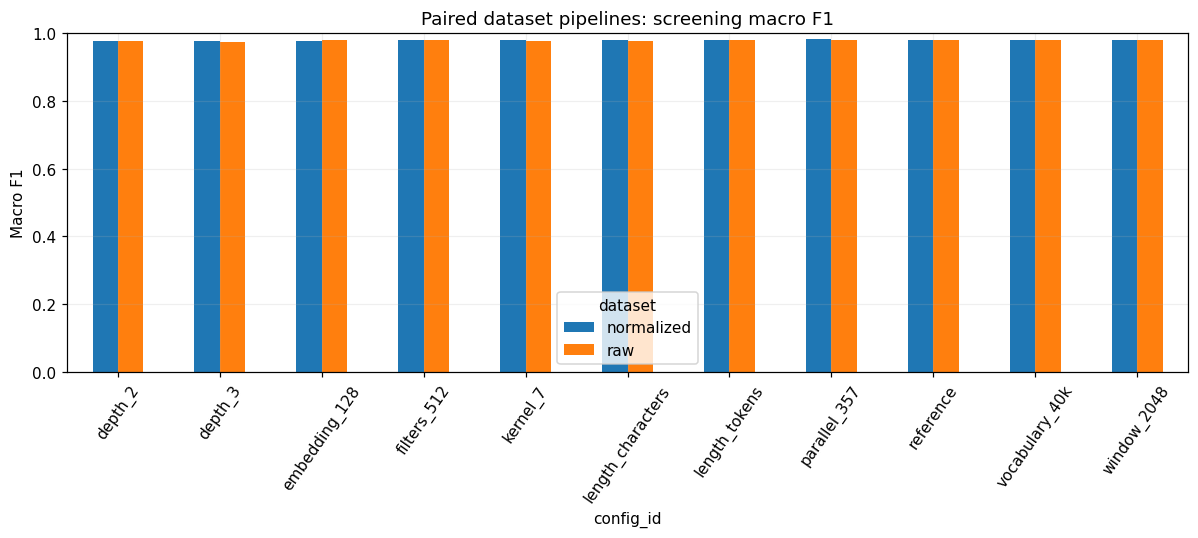

In [3]:
def comparison_table(entries):
    fields = ("dataset", "config_id", "status", "macro_f1_mean",
              "macro_f1_std", "parameter_count")
    return pd.DataFrame([{key: e.get(key) for key in fields} for e in entries])
screening = exp.read_json(RUN_DIR / "screening" / "results.json")["entries"]
confirmation = exp.read_json(RUN_DIR / "confirmation" / "results.json")["entries"]
display(comparison_table(screening))
display(comparison_table(confirmation))

paired = comparison_table(screening)
paired = paired[paired["dataset"].isin(["raw", "normalized"]) & paired["status"].eq("complete")]
pivot = paired.pivot(index="config_id", columns="dataset", values="macro_f1_mean")
fig, ax = plt.subplots(figsize=(11, 5))
pivot.plot.bar(ax=ax)
ax.set(title="Paired dataset pipelines: screening macro F1", ylabel="Macro F1", ylim=(0, 1))
ax.tick_params(axis="x", labelrotation=55)
fig.tight_layout()
plt.show()
plt.close(fig)

## 4. Compare controlled preprocessing

These cases share source records and fold assignments. The folder comparison also changes retained rows; it does not isolate a causal lowercasing effect.

In [4]:
controlled = comparison_table(screening)
display(controlled[controlled["dataset"].eq("controlled")])
controls = exp.read_json(RUN_DIR / "length_baselines" / "results.json")["entries"]
display(pd.DataFrame([{"dataset": r["dataset"], "feature": r["feature"],
                      "macro_f1_mean": r["macro_f1_mean"]} for r in controls]))

,dataset,config_id,status,macro_f1_mean,macro_f1_std,parameter_count
22,controlled,case_0_keep,complete,0.983641,0.003481,1362433.0
23,controlled,case_0_remove_bang_question,complete,0.982207,0.003249,1362433.0
24,controlled,case_0_words_only,complete,0.977320,0.004367,1362433.0
25,controlled,case_1_keep,complete,0.980721,0.002961,1362433.0
26,controlled,case_1_remove_bang_question,complete,0.980455,0.002035,1362433.0
27,controlled,case_1_words_only,complete,0.967866,0.003460,1362433.0


,dataset,feature,macro_f1_mean
0,raw,log_tokens,0.691548
1,raw,log_characters,0.663632
2,normalized,log_tokens,0.687213
3,normalized,log_characters,0.661142


## 5. Score validation and calibrate development thresholds

Calibration uses identical source rows across datasets, excluding any tested-tokenizer collision with either training variant. Threshold 0.5 remains the primary reference. Additional profiles prioritize balanced macro F1, low false alarms, or high detection. None of these settings uses test scores.

In [5]:
validation = study.analyze_validation(RUN_DIR, device=DEVICE)
metrics = pd.DataFrame(validation["reports"])
columns = ["model", "split", "profile", "rows", "threshold", "macro_f1",
           "injection_precision", "injection_recall", "injection_f1", "false_positive_rate",
           "average_precision"]
display(metrics[columns])
display(pd.DataFrame(validation["coverage"]).T)

,model,split,profile,rows,threshold,macro_f1,injection_precision,injection_recall,injection_f1,false_positive_rate,average_precision
0,raw_selected,validation_full_development,default,1000,0.500000,0.979999,0.991853,0.968191,0.979879,0.008048,0.999153
1,raw_selected,validation_full_development,balanced,1000,0.138430,0.984998,0.980315,0.990060,0.985163,0.020121,0.999153
2,raw_selected,validation_full_development,low_false_alarms,1000,0.424756,0.984000,0.991919,0.976143,0.983968,0.008048,0.999153
3,raw_selected,validation_full_development,high_detection,1000,0.082489,0.976988,0.961538,0.994036,0.977517,0.040241,0.999153
4,raw_selected,validation_common_disjoint_development,default,976,0.500000,0.979489,0.991435,0.966597,0.978858,0.008048,0.999067
...,...,...,...,...,...,...,...,...,...,...,...
91,normalized_log_characters,validation_common_disjoint_development,high_detection,976,0.340224,0.777880,0.697947,0.993737,0.819983,0.414487,0.664773
92,normalized_log_characters,validation_length_matched_development,default,476,0.500000,0.466875,0.479730,0.596639,0.531835,0.647059,0.471589
93,normalized_log_characters,validation_length_matched_development,balanced,476,0.382163,0.519878,0.548544,0.949580,0.695385,0.781513,0.471589
94,normalized_log_characters,validation_length_matched_development,low_false_alarms,476,0.928884,0.330520,0.000000,0.000000,0.000000,0.012605,0.471589


,full_rows,common_disjoint_rows,length_matched_rows
raw_selected,1000,976,476
raw_reference,1000,976,476
raw_log_tokens,1000,976,476
raw_log_characters,1000,976,476
normalized_selected,1000,976,476
normalized_reference,1000,976,476
normalized_log_tokens,1000,976,476
normalized_log_characters,1000,976,476


## 6. Inspect confusion matrices on common eligible validation rows

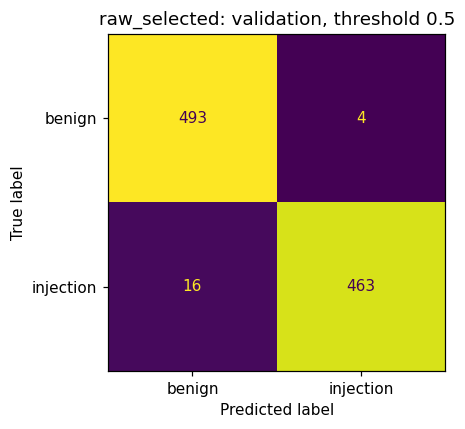

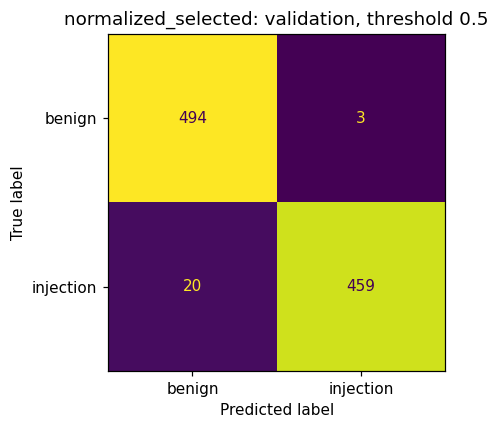

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
eligible = set(validation["metadata"]["calibration_source_rows"])
validation_predictions = {}
for name in ("raw_selected", "normalized_selected"):
    spec = validation["predictions"][name]
    scored = pd.read_json(RUN_DIR / spec["path"], lines=True)
    scored = scored[scored["source_row"].isin(eligible)]
    validation_predictions[name] = scored
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        scored["label"], scored["injection_score"].ge(0.5).astype(int),
        labels=[0, 1], display_labels=["benign", "injection"], colorbar=False, ax=ax,
    )
    ax.set_title(f"{name}: validation, threshold 0.5")
    ax.grid(False)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 7. Inspect ROC and precision-recall curves

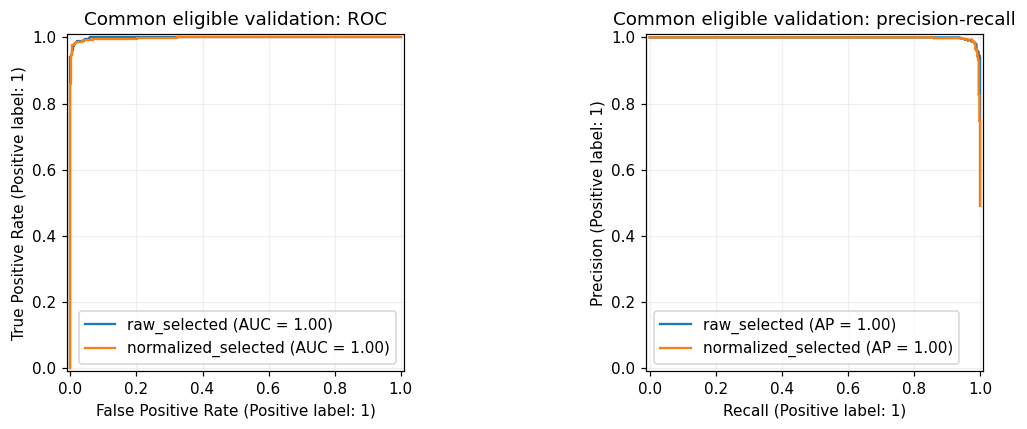

In [7]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, scored in validation_predictions.items():
    RocCurveDisplay.from_predictions(scored["label"], scored["injection_score"], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(scored["label"], scored["injection_score"], name=name, ax=axes[1])
axes[0].set_title("Common eligible validation: ROC")
axes[1].set_title("Common eligible validation: precision-recall")
fig.tight_layout()
plt.show()
plt.close(fig)

## 8. Check lengths, truncation, and unknown words

Length bands use training-derived original token-count quartiles. Long benign examples and short injections deserve separate inspection. The length-matched development subset balances labels within each band; its class proportions differ from the full data.

In [8]:
length_rows = [{"model": name, **row}
               for name, rows in validation["length_slices"].items() for row in rows]
display(pd.DataFrame(length_rows))
display(pd.DataFrame(validation["input_diagnostics"]).T)
for name in ("raw_selected", "normalized_selected"):
    path = RUN_DIR / validation["input_diagnostics"][name]["path"]
    diagnostics = pd.read_json(path, lines=True)
    print(name, "error summaries")
    display(diagnostics.groupby("error_type").agg(
        rows=("source_row", "size"), median_original_tokens=("original_tokens", "median"),
        truncated_rows=("truncated", "sum"), mean_unknown_rate=("unknown_token_rate", "mean"),
    ))
    display(diagnostics[diagnostics["error_type"].ne("correct")].head(12))

,model,length_band,rows,benign_rows,injection_rows,false_positive_rate,injection_recall
0,raw_selected,1,259,259,0,0.000000,NaN
1,raw_selected,2,245,90,155,0.022222,0.929032
2,raw_selected,3,243,83,160,0.012048,0.987500
3,raw_selected,4,229,65,164,0.015385,0.981707
4,raw_reference,1,259,259,0,0.000000,NaN
5,raw_reference,2,245,90,155,0.033333,0.929032
6,raw_reference,3,243,83,160,0.012048,0.987500
7,raw_reference,4,229,65,164,0.015385,0.987805
8,raw_log_tokens,1,259,259,0,0.000000,NaN
9,raw_log_tokens,2,245,90,155,0.011111,0.154839


,path,truncated_rows,mean_unknown_token_rate
raw_selected,analysis\raw_selected_validation_diagnostics.j...,7,0.025171
raw_reference,analysis\raw_reference_validation_diagnostics....,7,0.016676
normalized_selected,analysis\normalized_selected_validation_diagno...,7,0.01671
normalized_reference,analysis\normalized_reference_validation_diagn...,7,0.01671


raw_selected error summaries


,rows,median_original_tokens,truncated_rows,mean_unknown_rate
error_type,,,,
correct,980,63.0,7,0.025208
false_negative,16,50.5,0,0.018281
false_positive,4,57.0,0,0.043783


,source_row,row_index,label,prediction,injection_score,original_characters,original_tokens,model_tokens,truncated,unknown_token_rate,error_type
49,49,49,1,0,0.039558,143,26,26,False,0.038462,false_negative
89,89,89,1,0,0.085907,1076,200,200,False,0.040000,false_negative
119,119,119,0,1,0.965481,221,30,30,False,0.000000,false_positive
122,122,122,1,0,0.082489,224,46,46,False,0.021739,false_negative
294,294,294,1,0,0.338183,152,35,35,False,0.028571,false_negative
311,311,311,1,0,0.066372,243,49,49,False,0.000000,false_negative
335,335,335,1,0,0.470641,257,42,42,False,0.023810,false_negative
350,350,350,1,0,0.226184,290,64,64,False,0.000000,false_negative
359,359,359,1,0,0.152934,276,52,52,False,0.019231,false_negative
383,383,383,1,0,0.424756,258,55,55,False,0.000000,false_negative


normalized_selected error summaries


,rows,median_original_tokens,truncated_rows,mean_unknown_rate
error_type,,,,
correct,977,63.0,7,0.016707
false_negative,20,50.5,0,0.012742
false_positive,3,84.0,0,0.044004


,source_row,row_index,label,prediction,injection_score,original_characters,original_tokens,model_tokens,truncated,unknown_token_rate,error_type
49,49,49,1,0,0.088296,143,26,26,False,0.038462,false_negative
77,77,77,1,0,0.105670,213,42,42,False,0.000000,false_negative
83,83,83,1,0,0.056888,173,32,32,False,0.031250,false_negative
89,89,89,1,0,0.145755,1076,200,200,False,0.025000,false_negative
113,113,113,1,0,0.440961,263,52,52,False,0.000000,false_negative
119,119,119,0,1,0.982995,221,30,30,False,0.000000,false_positive
122,122,122,1,0,0.021360,224,46,46,False,0.000000,false_negative
193,193,193,1,0,0.313557,416,65,65,False,0.030769,false_negative
195,195,195,1,0,0.289908,252,49,49,False,0.000000,false_negative
238,238,238,1,0,0.400391,272,62,62,False,0.016129,false_negative


## 9. Inspect neutral-padding sensitivity

The complete original text and appended neutral words fit within the model window. Labels are assumed unchanged; review examples before interpreting. Score changes are diagnostics, not an automatic pass/fail rule.

In [9]:
display(pd.DataFrame([{
    "model": name, **{key: row.get(key) for key in
                     ("rows", "mean_absolute_score_change", "prediction_flips_at_0.5")}
} for name, row in validation["neutral_padding"].items()]))

,model,rows,mean_absolute_score_change,prediction_flips_at_0.5
0,raw_selected,200,0.010197,2
1,normalized_selected,200,0.018622,4


## 10. Freeze models and decision thresholds

This records checkpoint identities and calibration thresholds before any optional test scoring.

In [10]:
FROZEN_PATH = study.freeze_study(RUN_DIR)
print("Frozen evaluation:", FROZEN_PATH)

Frozen evaluation: cnn\artifacts\cnn_study_v2_full_01\analysis\frozen_evaluation.json


## 11. Optional: evaluate the known test benchmark

Keep disabled throughout search and development. After freezing a full study, enabling this evaluates each dataset's complete test split and identical common training-disjoint source records. Thresholds are loaded from the frozen record. Results remain known-benchmark results.

In [11]:
if RUN_TEST:
    test_report = study.evaluate_study_test(RUN_DIR, device=DEVICE)
    test_metrics = pd.DataFrame(test_report["reports"])
    display(test_metrics[columns])
    display(pd.DataFrame([{"model": name, **row}
                         for name, rows in test_report["length_slices"].items() for row in rows]))
else:
    print("Test scoring is disabled. No test data opened.")

,model,split,profile,rows,threshold,macro_f1,injection_precision,injection_recall,injection_f1,false_positive_rate,average_precision
0,raw_selected,test_full_known_benchmark,default,23516,0.500000,0.752363,0.643212,0.638452,0.640823,0.134880,0.630122
1,raw_selected,test_full_known_benchmark,balanced,23516,0.138430,0.716726,0.527223,0.768887,0.625525,0.262595,0.630122
2,raw_selected,test_full_known_benchmark,low_false_alarms,23516,0.424756,0.738144,0.599607,0.658958,0.627883,0.167587,0.630122
3,raw_selected,test_full_known_benchmark,high_detection,23516,0.082489,0.699777,0.499471,0.800031,0.614993,0.305344,0.630122
4,raw_selected,test_common_disjoint_known_benchmark,default,23358,0.500000,0.751810,0.643412,0.638452,0.640922,0.136024,0.631412
...,...,...,...,...,...,...,...,...,...,...,...
59,normalized_log_characters,test_full_known_benchmark,high_detection,23359,0.340224,0.521185,0.367312,1.000000,0.537276,0.662123,0.558041
60,normalized_log_characters,test_common_disjoint_known_benchmark,default,23358,0.500000,0.666178,0.457407,0.999229,0.627548,0.455666,0.558041
61,normalized_log_characters,test_common_disjoint_known_benchmark,balanced,23358,0.382163,0.547752,0.380433,1.000000,0.551179,0.626067,0.558041
62,normalized_log_characters,test_common_disjoint_known_benchmark,low_false_alarms,23358,0.928884,0.445190,0.772093,0.025594,0.049545,0.002904,0.558041


,model,length_band,rows,benign_rows,injection_rows,false_positive_rate,injection_recall
0,raw_selected,1,4931,4931,0,0.002028,NaN
1,raw_selected,2,3735,3715,20,0.149664,0.450000
2,raw_selected,3,5225,3769,1456,0.233218,0.774038
3,raw_selected,4,9467,4457,5010,0.190711,0.599800
4,raw_reference,1,4931,4931,0,0.001420,NaN
5,raw_reference,2,3735,3715,20,0.209152,0.800000
6,raw_reference,3,5225,3769,1456,0.420005,0.733516
7,raw_reference,4,9467,4457,5010,0.365268,0.627944
8,raw_log_tokens,1,4931,4931,0,0.000000,NaN
9,raw_log_tokens,2,3735,3715,20,0.097712,0.650000


## 12. Optional: compare the CNNs with saved PromptShield TF-IDF results

The raw full-test baseline reuses saved metrics. The normalized and exact-deduplicated full-test baselines come from the [cleaned PromptShield analysis](../analysis/promptshield_analysis.ipynb). The shared training-disjoint baselines reuse the previously computed scores on those 23,358 rows. The baselines use 20,000 word TF-IDF features and logistic regression with seed 42. All comparisons use threshold 0.5.

For the exact-deduplicated split, the training prompts and labels match the raw training set. The comparison selects the corresponding rows from the saved raw CNN predictions. Set `RUN_TEST = True` in step 2 and run through this section to refresh the CNN comparison. The saved TF-IDF metrics are reused on each run.

In [12]:
if RUN_TEST:
    from hashlib import sha256

    full_split = "test_full_known_benchmark"
    common_split = "test_common_disjoint_known_benchmark"
    comparison_columns = [
        "dataset", "model", "rows", "threshold", "accuracy", "macro_f1", "injection_precision",
        "injection_recall", "injection_f1", "false_positive_rate", "false_positives",
        "false_negatives", "roc_auc", "average_precision",
    ]
    baseline_columns = ["dataset", "split"] + comparison_columns[2:3] + comparison_columns[4:]
    # Saved full-test results from PromptShield and shared-subset results from the earlier study comparison.
    baseline_results = pd.DataFrame([
        ("raw", full_split, 23516, .7027, .5950, .4485, .3390, .3862, .1588, 2704, 4287, .7421, .4442),
        ("normalized", full_split, 23359, .7026, .5939, .4519, .3335, .3838, .1555, 2623, 4323, .7416, .4458),
        ("exact", full_split, 23359, .7032, .5961, .4540, .3390, .3882, .1568, 2645, 4287, .7429, .4479),
        ("raw", common_split, 23358, .7032, .5961, .4540, .3390, .3882, .1568, 2645, 4287, .7429, .4479),
        ("normalized", common_split, 23358, .7026, .5939, .4519, .3335, .3838, .1555, 2623, 4323, .7415, .4458),
    ], columns=baseline_columns).assign(model="TF-IDF + logistic regression", threshold=0.5)

    manifest = study.load_suite(RUN_DIR)["manifest"]
    dataset_dirs = {**manifest["datasets"], "exact": ROOT / "cleaning" / "data" / "exact"}
    # SHA-256 of the train and test JSON files with LF line endings.
    baseline_hashes = {
        "raw": (
            "aa33c3ffcc27bd07c0a233b52f1b8c3cbdb30606ce2412da06a88b5290cdc7b6",
            "d5b39f08718576720df788fe4cd482f608717cafabd68c4952046f1277464778",
        ),
        "normalized": (
            "ec3415119cf2516a78707bde0e8ca8d018f0425b7aab70b73a99bd664f92eecd",
            "9cc98468caed37a53426133395fade129208b0f416bdf6ffd80ab84a64d48141",
        ),
        "exact": (
            "fc485eefd0deb536969cd1b311084168f7761a565d6c7ac9ddff7fa28107d60c",
            "b9cbabe9b2e160e8e25764db9ef0b2d758ad0bef416702e0208ff028b5c36d28",
        ),
    }
    for variant, directory in dataset_dirs.items():
        hashes = tuple(sha256((Path(directory) / f"{split}.json").read_bytes()
                              .replace(b"\r\n", b"\n")).hexdigest() for split in ("train", "test"))
        if hashes != baseline_hashes[variant]:
            raise ValueError(f"The saved TF-IDF metrics use different {variant} train or test data.")

    frozen = exp.read_json(FROZEN_PATH)
    if exp.fingerprint(frozen["metadata"]) != test_report["identity"]["freeze_signature"]:
        raise ValueError("Frozen evaluation changed. Rerun step 11.")
    for variant in ("raw", "normalized"):
        exp._verify_artifact(Path(dataset_dirs[variant]) / "test.json",
                             test_report["identity"]["test_sha256"][variant])
    test_datasets = study.load_datasets(dataset_dirs["raw"], dataset_dirs["normalized"], "test")
    normalized_ids = {row["source_row"] for row in test_datasets["normalized"]}
    train_keys = set(frozen["metadata"]["training_collision_keys"])
    eligible_ids = sorted(row["source_row"] for row in test_datasets["raw"]
                          if row["source_row"] in normalized_ids
                          and study.collision_key(study.original_text(row)) not in train_keys)
    if exp.fingerprint(eligible_ids) != "b910fe99b1c48b0b0a2138b331884a082440a5b06af99954f2d9e26fb29d0bb3":
        raise ValueError("The saved shared-subset TF-IDF metrics use different test rows.")

    exact_rows = exp.read_split(dataset_dirs["exact"], "test")
    raw_source_ids = {}
    for row in test_datasets["raw"]:
        raw_source_ids.setdefault((row["prompt"], row["label"]), row["source_row"])
    exact_ids = [raw_source_ids[(row["prompt"], row["label"])] for row in exact_rows]
    exact_labels = np.array([row["label"] for row in exact_rows])

    cnn_results = test_metrics.loc[test_metrics["profile"].eq("default")].set_index(["model", "split"])
    comparison_rows = []
    for baseline in baseline_results.to_dict("records"):
        variant, split, threshold = baseline["dataset"], baseline["split"], baseline["threshold"]
        for role in ("selected", "reference"):
            if variant == "exact":
                spec = test_report["predictions"][f"raw_{role}"]
                prediction_file = RUN_DIR / spec["path"]
                exp._verify_artifact(prediction_file, spec["sha256"])
                predictions = pd.read_json(prediction_file, lines=True, precise_float=True)
                exact_predictions = predictions.set_index("source_row").loc[exact_ids]
                if not np.array_equal(exact_predictions["label"], exact_labels):
                    raise ValueError("Raw CNN predictions do not align with the exact test labels.")
                cnn_metrics = exp.binary_metrics(exact_labels, exact_predictions["injection_score"], threshold)
            else:
                cnn_metrics = cnn_results.loc[(f"{variant}_{role}", split)].to_dict()
                if cnn_metrics["threshold"] != threshold:
                    raise ValueError(f"Different CNN and TF-IDF thresholds for {variant} / {split}.")
            if cnn_metrics["rows"] != baseline["rows"]:
                raise ValueError(f"Different CNN and TF-IDF row counts for {variant} / {split}.")
            comparison_rows.append({**cnn_metrics, "dataset": variant, "split": split, "threshold": threshold,
                                    "model": f"CNN ({role})"})
        comparison_rows.append(baseline)

    test_comparison = pd.DataFrame(comparison_rows)
    for split, title in ((full_split, "Full test splits"), (common_split, "Common training-disjoint test rows")):
        print(title)
        display(test_comparison.loc[test_comparison["split"].eq(split), comparison_columns]
                .reset_index(drop=True).round(4))
else:
    print("Set RUN_TEST = True to compare the CNNs with the saved TF-IDF results.")

Full test splits


,dataset,model,rows,threshold,accuracy,macro_f1,injection_precision,injection_recall,injection_f1,false_positive_rate,false_positives,false_negatives,roc_auc,average_precision
0,raw,CNN (selected),23516,0.5,0.8026,0.7524,0.6432,0.6385,0.6408,0.1349,2297,2345,0.8288,0.6301
1,raw,CNN (reference),23516,0.5,0.7341,0.6908,0.5142,0.6522,0.5750,0.2347,3997,2256,0.8069,0.6012
2,raw,TF-IDF + logistic regression,23516,0.5,0.7027,0.5950,0.4485,0.3390,0.3862,0.1588,2704,4287,0.7421,0.4442
3,normalized,CNN (selected),23359,0.5,0.7169,0.6689,0.4921,0.6053,0.5429,0.2401,4052,2560,0.7930,0.6003
4,normalized,CNN (reference),23359,0.5,0.6851,0.6534,0.4557,0.6895,0.5487,0.3166,5342,2014,0.7827,0.5963
5,normalized,TF-IDF + logistic regression,23359,0.5,0.7026,0.5939,0.4519,0.3335,0.3838,0.1555,2623,4323,0.7416,0.4458
6,exact,CNN (selected),23359,0.5,0.8014,0.7518,0.6434,0.6385,0.6409,0.1360,2295,2345,0.8290,0.6314
7,exact,CNN (reference),23359,0.5,0.7324,0.6899,0.5143,0.6522,0.5751,0.2368,3995,2256,0.8066,0.6020
8,exact,TF-IDF + logistic regression,23359,0.5,0.7032,0.5961,0.4540,0.3390,0.3882,0.1568,2645,4287,0.7429,0.4479


Common training-disjoint test rows


,dataset,model,rows,threshold,accuracy,macro_f1,injection_precision,injection_recall,injection_f1,false_positive_rate,false_positives,false_negatives,roc_auc,average_precision
0,raw,CNN (selected),23358,0.5,0.8014,0.7518,0.6434,0.6385,0.6409,0.1360,2295,2345,0.8290,0.6314
1,raw,CNN (reference),23358,0.5,0.7324,0.6899,0.5143,0.6522,0.5751,0.2368,3995,2256,0.8066,0.6020
2,raw,TF-IDF + logistic regression,23358,0.5,0.7032,0.5961,0.4540,0.3390,0.3882,0.1568,2645,4287,0.7429,0.4479
3,normalized,CNN (selected),23358,0.5,0.7169,0.6689,0.4921,0.6053,0.5429,0.2402,4052,2560,0.7930,0.6003
4,normalized,CNN (reference),23358,0.5,0.6851,0.6534,0.4557,0.6895,0.5487,0.3166,5342,2014,0.7827,0.5963
5,normalized,TF-IDF + logistic regression,23358,0.5,0.7026,0.5939,0.4519,0.3335,0.3838,0.1555,2623,4323,0.7415,0.4458
